# WiCount CSI Exploration and Visualization

Eksplorasi ini membaca **dataset WiCount asli** dari arsip ZIP hasil clone Hugging Face tanpa mengekstrak atau mengubah dataset. Label okupansi berasal dari folder `data/0` sampai `data/3` di arsip. Visualisasi 3D memakai satu rekaman deterministik per kelas; hasilnya bersifat deskriptif dan bukan bukti sebab-akibat.

## Section 1 - Environment

Impor library analisis, cari root proyek secara relatif dari working directory notebook, dan pastikan arsip dataset yang telah di-clone tersedia.

In [1]:
from pathlib import Path, PurePosixPath
from io import BytesIO
import json
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next(
    (path for path in candidates if (path / "PRD.md").is_file() and (path / "analysis").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the WiFiSENSE project root. Open/run this notebook from the project or a child directory."
    )

DATASET_DIR = PROJECT_ROOT / "analysis" / "dataset" / "WiCount"
DATASET_ZIP = DATASET_DIR / "WiCount.zip"
OUTPUT_DIR = PROJECT_ROOT / "analysis" / "outputs"
if not DATASET_ZIP.is_file():
    raise FileNotFoundError(f"WiCount archive not found: {DATASET_ZIP}")

print("Project root: . (resolved from notebook working directory)")
print(f"Dataset archive: {DATASET_ZIP.relative_to(PROJECT_ROOT)} ({DATASET_ZIP.stat().st_size:,} bytes)")
print(f"NumPy {np.__version__}; pandas {pd.__version__}; SciPy {scipy.__version__}")

Project root: . (resolved from notebook working directory)
Dataset archive: analysis\dataset\WiCount\WiCount.zip (9,389,189 bytes)
NumPy 2.5.2; pandas 3.0.5; SciPy 1.18.1


## Section 2 - Dataset Exploration

Daftar CSV dan jumlah record dibaca langsung dari ZIP secara berurutan agar tidak perlu mengekstrak arsip. Sampling untuk inspeksi hanya membaca beberapa baris.

In [2]:
with zipfile.ZipFile(DATASET_ZIP) as archive:
    csv_members = sorted(
        name for name in archive.namelist()
        if name.lower().endswith(".csv") and len(PurePosixPath(name).parts) >= 3
    )
    if not csv_members:
        raise ValueError("No CSV recordings found under data/<occupancy>/ in the WiCount archive.")

    file_records = []
    for member in csv_members:
        parts = PurePosixPath(member).parts
        if parts[0] != "data" or parts[1] not in {"0", "1", "2", "3"}:
            continue
        row_count = 0
        with archive.open(member) as csv_stream:
            for chunk in pd.read_csv(csv_stream, usecols=["seq"], chunksize=5000):
                row_count += len(chunk)
        file_records.append({"occupancy": int(parts[1]), "file": member, "samples": row_count})

file_counts = pd.DataFrame(file_records).sort_values(["occupancy", "file"]).reset_index(drop=True)
class_counts = (
    file_counts.groupby("occupancy")["samples"].sum()
    .reindex([0, 1, 2, 3], fill_value=0)
    .rename("samples")
    .to_frame()
)
print(f"CSV recordings: {len(file_counts)}")
display(file_counts)
print("Samples by occupancy folder:")
display(class_counts)

with zipfile.ZipFile(DATASET_ZIP) as archive:
    first_member = file_counts.iloc[0]["file"]
    with archive.open(first_member) as csv_stream:
        sample = pd.read_csv(csv_stream, nrows=3)
print(f"Columns ({len(sample.columns)}): {sample.columns.tolist()}")
print(f"Sample rows from {first_member} (MAC masked; CSI payload shortened for display):")
sample_display = sample.copy()
if "mac" in sample_display.columns:
    sample_display["mac"] = "[masked]"
sample_display["data"] = sample_display["data"].astype(str).str.slice(0, 120) + "..."
display(sample_display)

CSV recordings: 15


,occupancy,file,samples
0,0,data/0/2023-12-21_19-23-53-985_104_1.csv,5218
1,1,data/1/2023-12-21_19-27-21-930_104_1.csv,4780
2,1,data/1/2023-12-21_19-31-17-706_104_1.csv,5189
3,1,data/1/2023-12-21_19-34-42-783_104_1.csv,5234
4,1,data/1/2023-12-21_19-37-36-861_104_1.csv,5163
5,1,data/1/2023-12-21_19-40-12-110_104_1.csv,5421
6,1,data/1/2023-12-21_19-42-28-267_104_1.csv,5644
7,1,data/1/2023-12-21_19-45-07-501_104_1.csv,5128
8,2,data/2/2023-12-21_19-47-14-669_104_1.csv,5376
9,2,data/2/2023-12-21_19-49-37-940_104_1.csv,5307


Samples by occupancy folder:


,samples
occupancy,
0,5218
1,36559
2,31935
3,4906


Columns (28): ['type', 'seq', 'timestamp', 'taget_seq', 'taget', 'mac', 'rssi', 'rate', 'sig_mode', 'mcs', 'cwb', 'smoothing', 'not_sounding', 'aggregation', 'stbc', 'fec_coding', 'sgi', 'noise_floor', 'ampdu_cnt', 'channel_primary', 'channel_secondary', 'local_timestamp', 'ant', 'sig_len', 'rx_state', 'len', 'first_word_invalid', 'data']
Sample rows from data/0/2023-12-21_19-23-53-985_104_1.csv (MAC masked; CSI payload shortened for display):


,type,seq,timestamp,taget_seq,taget,mac,rssi,rate,sig_mode,mcs,...,ampdu_cnt,channel_primary,channel_secondary,local_timestamp,ant,sig_len,rx_state,len,first_word_invalid,data
0,CSI_DATA,5608,2023-12-21 19:23:53.985,1,test,[masked],-27,11,0,0,...,0,12,2,67951197,0,37,0,104,0,"[-3, 9, -5, 7, -7, 6, -9, 6, -10, 6, -12, 6, -..."
1,CSI_DATA,5609,2023-12-21 19:23:54.001,1,test,[masked],-27,11,0,0,...,0,12,2,67961729,0,37,0,104,0,"[7, -7, 8, -5, 9, -3, 10, -2, 12, 0, 13, 0, 15..."
2,CSI_DATA,5610,2023-12-21 19:23:54.016,1,test,[masked],-27,11,0,0,...,0,12,2,67969731,0,37,0,104,0,"[-7, 5, -8, 3, -9, 2, -10, 0, -11, -1, -13, -1..."


## Section 3 - CSI Parsing

Dataset README menyatakan `data` sebagai 104 nilai dalam pasangan interleaved `[real, imaginary]`, yaitu 52 nilai CSI kompleks. Parser ini memvalidasi isi JSON, jumlah komponen, tipe numerik, dan nilai finite; baris invalid dikecualikan dari visualisasi dan dilaporkan.

In [3]:
EXPECTED_COMPONENTS = 104
EXPECTED_SUBCARRIERS = EXPECTED_COMPONENTS // 2


def parse_csi_pairs(payload):
    # Parse one source data field as 52 interleaved real/imaginary pairs.
    values = json.loads(payload) if isinstance(payload, str) else payload
    if not isinstance(values, list):
        raise ValueError("CSI payload is not a JSON list")
    if len(values) != EXPECTED_COMPONENTS:
        raise ValueError(f"Expected {EXPECTED_COMPONENTS} components, found {len(values)}")
    if any(isinstance(value, bool) or not isinstance(value, (int, float)) for value in values):
        raise ValueError("CSI payload contains a non-numeric component")
    components = np.asarray(values, dtype=np.float64)
    if not np.isfinite(components).all():
        raise ValueError("CSI payload contains a non-finite component")
    return components.reshape(EXPECTED_SUBCARRIERS, 2)


recording_for_class = {
    occupancy: file_counts.loc[file_counts["occupancy"] == occupancy, "file"].iloc[0]
    for occupancy in [0, 1, 2, 3]
    if (file_counts["occupancy"] == occupancy).any()
}


def load_recording(member):
    # Load one CSV from the ZIP and parse its payloads without changing source data.
    with zipfile.ZipFile(DATASET_ZIP) as archive, archive.open(member) as csv_stream:
        frame = pd.read_csv(csv_stream)

    parsed_pairs = []
    valid_indices = []
    invalid_rows = []
    for index, payload in enumerate(frame["data"]):
        try:
            parsed_pairs.append(parse_csi_pairs(payload))
            valid_indices.append(index)
        except (ValueError, TypeError) as error:
            invalid_rows.append({"row_index": index, "reason": str(error)})

    valid_frame = frame.iloc[valid_indices].reset_index(drop=True)
    if parsed_pairs:
        pairs = np.stack(parsed_pairs)
    else:
        pairs = np.empty((0, EXPECTED_SUBCARRIERS, 2), dtype=np.float64)
    return valid_frame, pairs, invalid_rows


parsed_recordings = {}
for occupancy, member in recording_for_class.items():
    frame, pairs, invalid_rows = load_recording(member)
    parsed_recordings[occupancy] = {"file": member, "frame": frame, "pairs": pairs, "invalid": invalid_rows}
    print(
        f"Class {occupancy}: {member} ? {len(frame)} valid rows, "
        f"{len(invalid_rows)} invalid CSI rows"
    )

print("Pair convention: data[2*i] = real and data[2*i+1] = imaginary for subcarrier i, as documented by WiCount.")

Class 0: data/0/2023-12-21_19-23-53-985_104_1.csv ? 5218 valid rows, 0 invalid CSI rows


Class 1: data/1/2023-12-21_19-27-21-930_104_1.csv ? 4780 valid rows, 0 invalid CSI rows


Class 2: data/2/2023-12-21_19-47-14-669_104_1.csv ? 5376 valid rows, 0 invalid CSI rows


Class 3: data/3/2023-12-21_20-07-25-709_104_1.csv ? 4906 valid rows, 0 invalid CSI rows
Pair convention: data[2*i] = real and data[2*i+1] = imaginary for subcarrier i, as documented by WiCount.


## Section 4 - CSI Amplitude Extraction

Sumber menyediakan pasangan real/imaginary, bukan amplitude terpisah. Maka amplitude dihitung per subcarrier dari `sqrt(real? + imaginary?)`; tidak ada transformasi yang diterapkan pada arsip raw.

In [4]:
amplitudes_by_class = {}
summary_rows = []
for occupancy, recording in parsed_recordings.items():
    pairs = recording["pairs"]
    amplitudes = np.sqrt(np.square(pairs[:, :, 0]) + np.square(pairs[:, :, 1]))
    amplitudes_by_class[occupancy] = amplitudes
    summary_rows.append({
        "occupancy": occupancy,
        "recording": PurePosixPath(recording["file"]).name,
        "valid_samples": amplitudes.shape[0],
        "subcarriers": amplitudes.shape[1],
        "mean_amplitude": float(np.mean(amplitudes)) if amplitudes.size else np.nan,
        "median_amplitude": float(np.median(amplitudes)) if amplitudes.size else np.nan,
    })

amplitude_summary = pd.DataFrame(summary_rows).sort_values("occupancy").reset_index(drop=True)
display(amplitude_summary)
assert all(array.shape[1] == EXPECTED_SUBCARRIERS for array in amplitudes_by_class.values())

,occupancy,recording,valid_samples,subcarriers,mean_amplitude,median_amplitude
0,0,2023-12-21_19-23-53-985_104_1.csv,5218,52,14.312227,13.341664
1,1,2023-12-21_19-27-21-930_104_1.csv,4780,52,14.157426,13.152946
2,2,2023-12-21_19-47-14-669_104_1.csv,5376,52,13.463463,12.727922
3,3,2023-12-21_20-07-25-709_104_1.csv,4906,52,13.549148,12.806248


## Section 5 - CSI Visualization 2D

Grafik berikut menggunakan data dari rekaman nyata yang dipilih pada tiap folder. Sumbu waktu pada dua grafik pertama menggunakan kolom `timestamp`; perbandingan kelas merangkum rata-rata subcarrier dari satu rekaman terpilih per kelas.

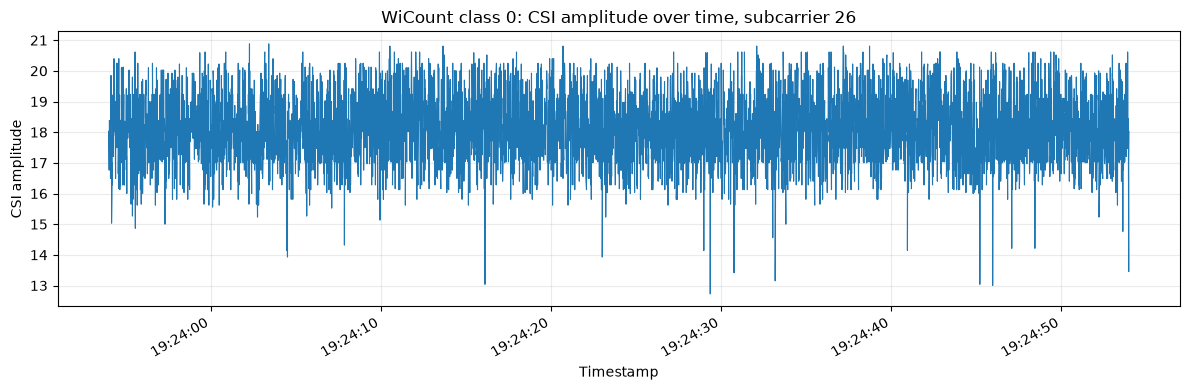

In [5]:
# Amplitude of one subcarrier over the recorded timestamps (class 0 recording).
reference_class = 0
reference = parsed_recordings[reference_class]
reference_times = pd.to_datetime(reference["frame"]["timestamp"], errors="coerce")
subcarrier_index = 25

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(reference_times, amplitudes_by_class[reference_class][:, subcarrier_index], linewidth=0.8)
ax.set(title=f"WiCount class {reference_class}: CSI amplitude over time, subcarrier {subcarrier_index + 1}",
       xlabel="Timestamp", ylabel="CSI amplitude")
ax.grid(True, alpha=0.25)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

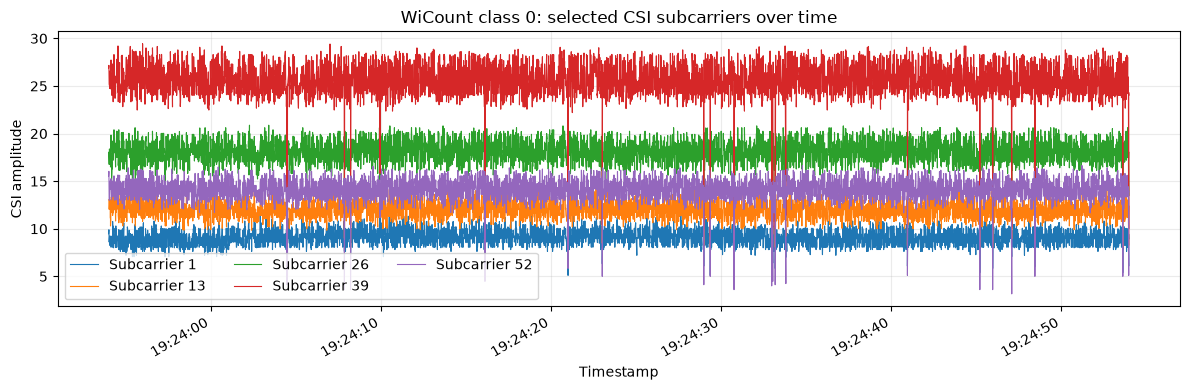

In [6]:
# Compare selected subcarriers over time in the same actual recording.
selected_subcarriers = [0, 12, 25, 38, 51]
fig, ax = plt.subplots(figsize=(12, 4))
for index in selected_subcarriers:
    ax.plot(reference_times, amplitudes_by_class[reference_class][:, index],
            linewidth=0.8, label=f"Subcarrier {index + 1}")
ax.set(title=f"WiCount class {reference_class}: selected CSI subcarriers over time",
       xlabel="Timestamp", ylabel="CSI amplitude")
ax.legend(ncol=3)
ax.grid(True, alpha=0.25)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

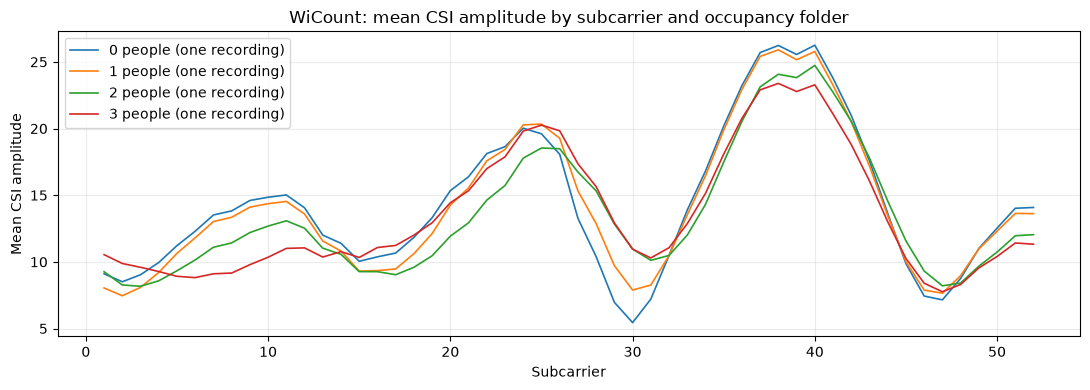

In [7]:
# Compare average per-subcarrier profiles from one selected recording per class.
fig, ax = plt.subplots(figsize=(11, 4))
subcarrier_numbers = np.arange(1, EXPECTED_SUBCARRIERS + 1)
for occupancy in sorted(amplitudes_by_class):
    ax.plot(subcarrier_numbers, amplitudes_by_class[occupancy].mean(axis=0),
            linewidth=1.2, label=f"{occupancy} people (one recording)")
ax.set(title="WiCount: mean CSI amplitude by subcarrier and occupancy folder",
       xlabel="Subcarrier", ylabel="Mean CSI amplitude")
ax.legend()
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

## Section 6 - CSI Visualization 3D

Setiap panel memakai satu file CSV asli per kelas; file yang dipilih adalah nama relatif pertama secara alfabetis. Baris disampling merata hanya untuk tampilan agar plot tetap ringan. Sumbu X adalah indeks time-step/row yang dipilih, Y adalah subcarrier, dan Z adalah amplitude. Batas Z yang sama dipakai untuk semua panel.

Saved 3D comparison: analysis\outputs\csi_3d_comparison.png


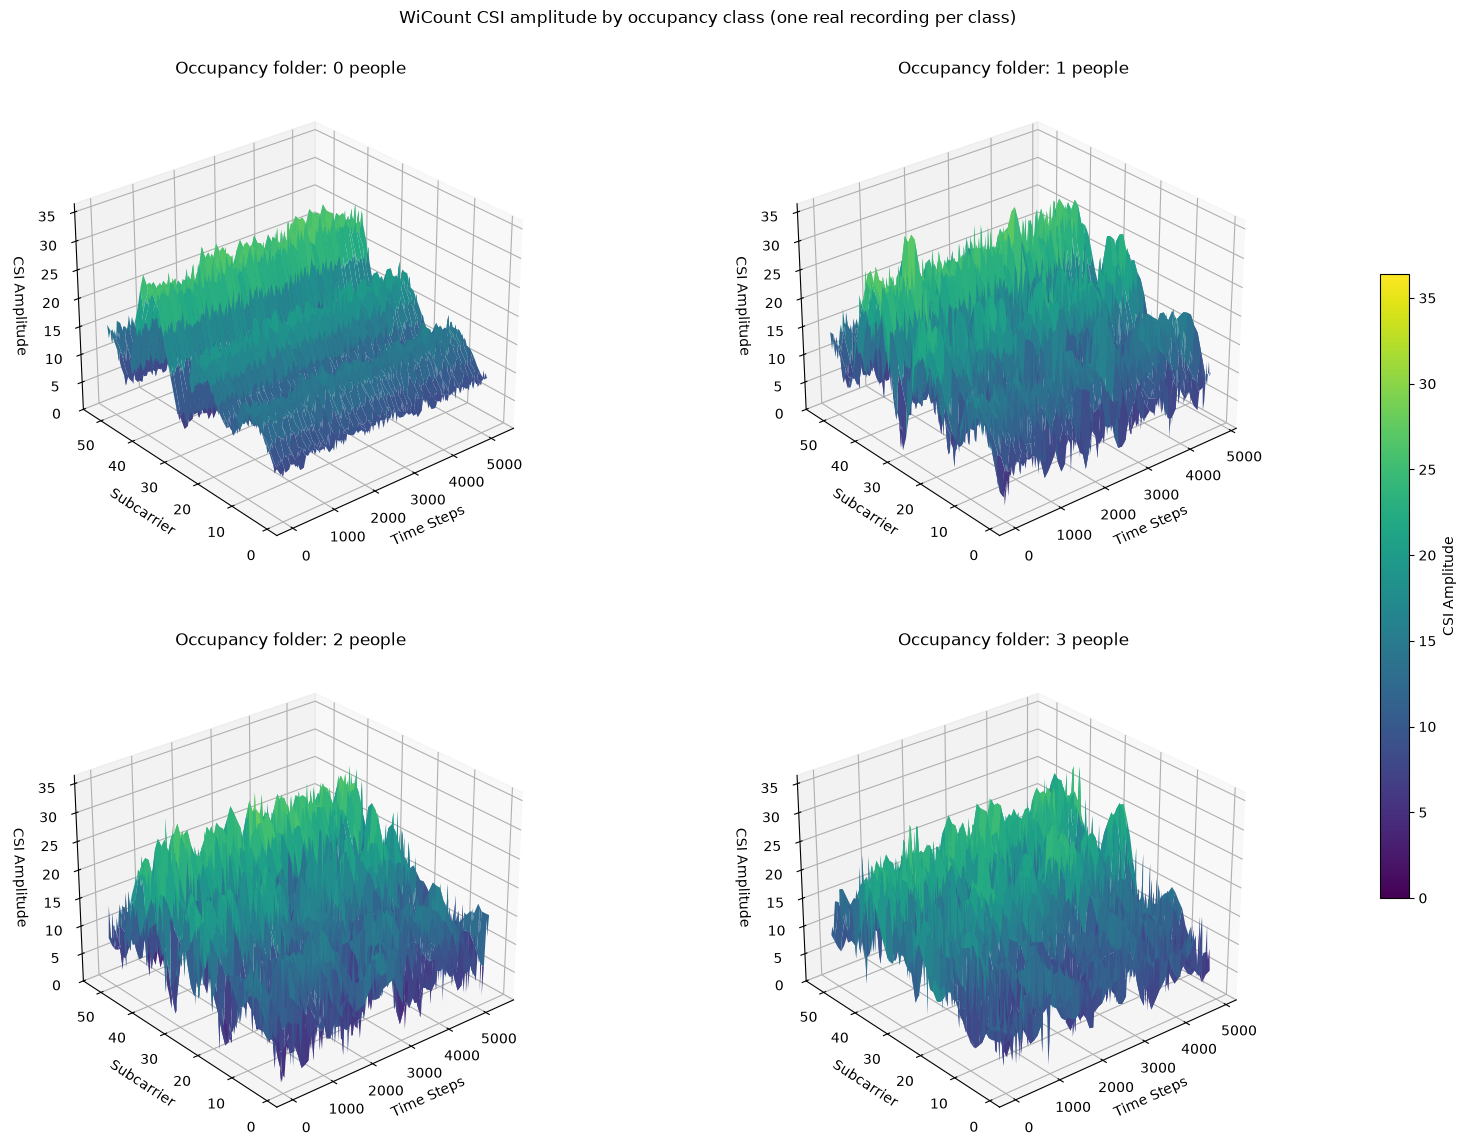

In [8]:
available_classes = sorted(amplitudes_by_class)
if available_classes != [0, 1, 2, 3]:
    raise ValueError(f"Expected occupancy folders 0, 1, 2, 3; found {available_classes}")

max_time_steps = 180
z_max = max(float(values.max()) for values in amplitudes_by_class.values() if values.size)
subcarrier_numbers = np.arange(1, EXPECTED_SUBCARRIERS + 1)
fig = plt.figure(figsize=(16, 12))

for panel_index, occupancy in enumerate(available_classes, start=1):
    values = amplitudes_by_class[occupancy]
    time_indices = np.unique(
        np.linspace(0, len(values) - 1, min(max_time_steps, len(values)), dtype=int)
    )
    selected = values[time_indices, :]
    x_grid, y_grid = np.meshgrid(time_indices, subcarrier_numbers)
    z_grid = selected.T

    ax = fig.add_subplot(2, 2, panel_index, projection="3d")
    surface = ax.plot_surface(x_grid, y_grid, z_grid, cmap="viridis",
                              linewidth=0, antialiased=True, vmin=0, vmax=z_max)
    ax.set(title=f"Occupancy folder: {occupancy} people",
           xlabel="Time Steps", ylabel="Subcarrier", zlabel="CSI Amplitude")
    ax.set_zlim(0, z_max)
    ax.view_init(elev=28, azim=-130)

fig.suptitle("WiCount CSI amplitude by occupancy class (one real recording per class)", y=0.98)
fig.subplots_adjust(left=0.03, right=0.90, bottom=0.04, top=0.92, wspace=0.08, hspace=0.18)
colorbar_axis = fig.add_axes([0.92, 0.24, 0.018, 0.52])
fig.colorbar(surface, cax=colorbar_axis, label="CSI Amplitude")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
output_path = OUTPUT_DIR / "csi_3d_comparison.png"
fig.savefig(output_path, dpi=160, bbox_inches="tight")
print(f"Saved 3D comparison: {output_path.relative_to(PROJECT_ROOT)}")
plt.show()

## Section 7 - Initial Analysis

Ringkasan numerik dan visualisasi ini bersifat deskriptif terhadap rekaman terpilih. Perbedaan amplitude dapat dipengaruhi oleh perangkat, posisi, multipath, aktivitas, dan kondisi ruangan; grafik ini tidak membuktikan bahwa okupansi adalah penyebab perubahan.

In [9]:
display(amplitude_summary[["occupancy", "valid_samples", "mean_amplitude", "median_amplitude"]])

variation_rows = []
for occupancy, values in sorted(amplitudes_by_class.items()):
    per_subcarrier_means = values.mean(axis=0)
    per_subcarrier_temporal_std = values.std(axis=0)
    variation_rows.append({
        "occupancy": occupancy,
        "median_temporal_std_across_subcarriers": float(np.median(per_subcarrier_temporal_std)),
        "range_of_subcarrier_mean_amplitude": float(np.ptp(per_subcarrier_means)),
    })
variation_summary = pd.DataFrame(variation_rows)
display(variation_summary)

mean_by_class = amplitude_summary.set_index("occupancy")["mean_amplitude"]
highest_class = int(mean_by_class.idxmax())
lowest_class = int(mean_by_class.idxmin())
print(
    "Selected-recording means are "
    + ", ".join(f"class {label}: {value:.3f}" for label, value in mean_by_class.items())
)
print(
    f"Among these four selected recordings, class {highest_class} has the highest mean amplitude "
    f"({mean_by_class.loc[highest_class]:.3f}) and class {lowest_class} the lowest "
    f"({mean_by_class.loc[lowest_class]:.3f}); the values are not a monotonic count trend."
)
print(
    "The 2D and 3D plots show within-record changes across time and subcarriers; "
    "the variation table quantifies this for the selected sessions. "
    "Only one selected recording represents each class in these comparisons, and classes 0 and 3 "
    "have one recording in the dataset. Environmental, placement, activity, and device factors "
    "are not controlled here, so these patterns do not establish that occupancy caused the changes."
)

,occupancy,valid_samples,mean_amplitude,median_amplitude
0,0,5218,14.312227,13.341664
1,1,4780,14.157426,13.152946
2,2,5376,13.463463,12.727922
3,3,4906,13.549148,12.806248


,occupancy,median_temporal_std_across_subcarriers,range_of_subcarrier_mean_amplitude
0,0,0.974843,20.806649
1,1,2.623195,18.446820
2,2,3.568689,16.563819
3,3,3.578290,15.624715


Selected-recording means are class 0: 14.312, class 1: 14.157, class 2: 13.463, class 3: 13.549
Among these four selected recordings, class 0 has the highest mean amplitude (14.312) and class 2 the lowest (13.463); the values are not a monotonic count trend.
The 2D and 3D plots show within-record changes across time and subcarriers; the variation table quantifies this for the selected sessions. Only one selected recording represents each class in these comparisons, and classes 0 and 3 have one recording in the dataset. Environmental, placement, activity, and device factors are not controlled here, so these patterns do not establish that occupancy caused the changes.
